<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


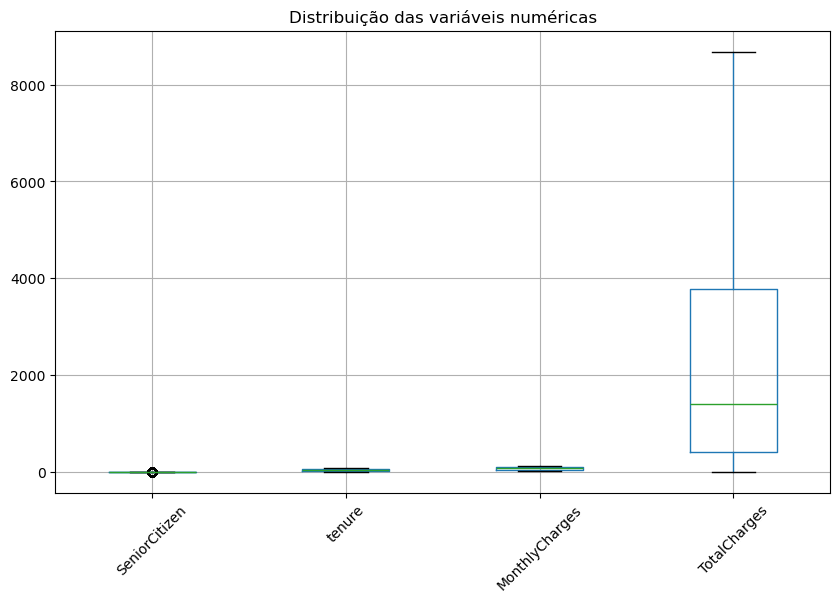

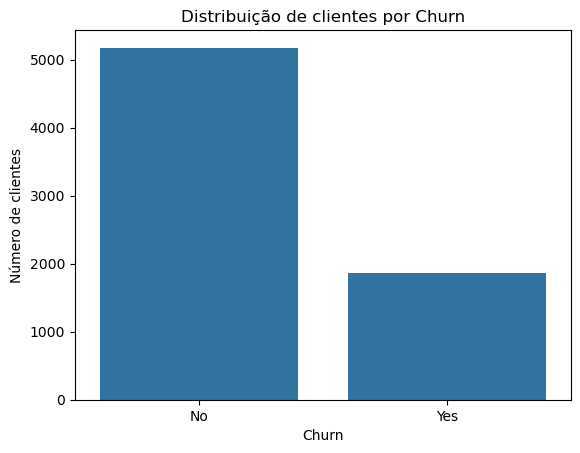

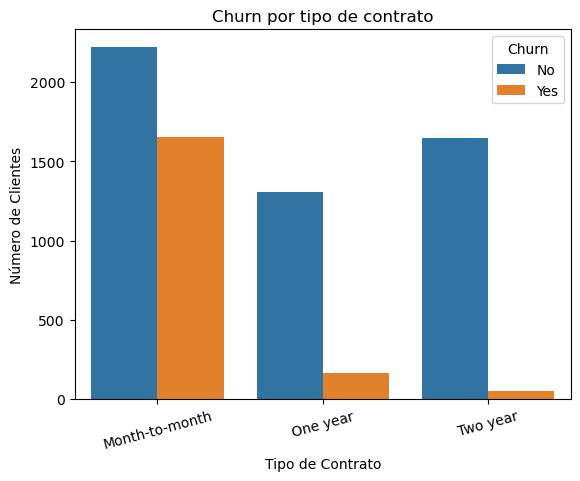

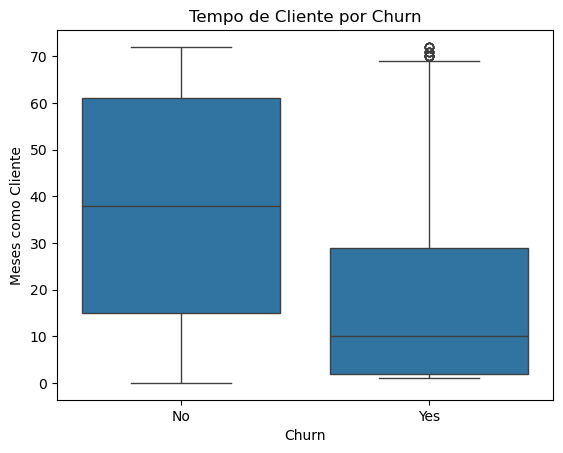

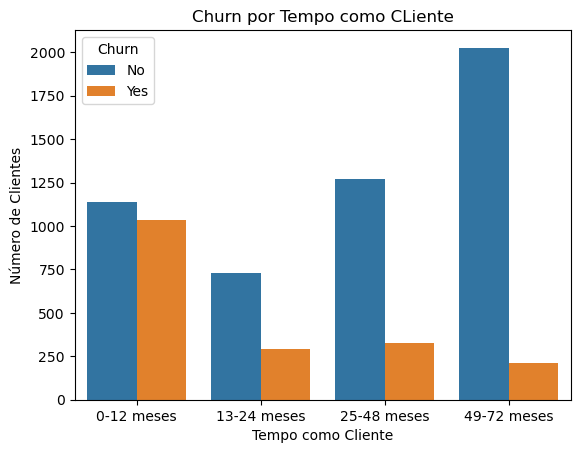

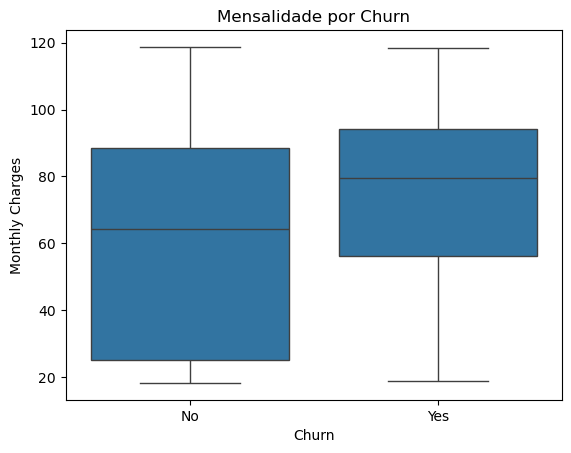

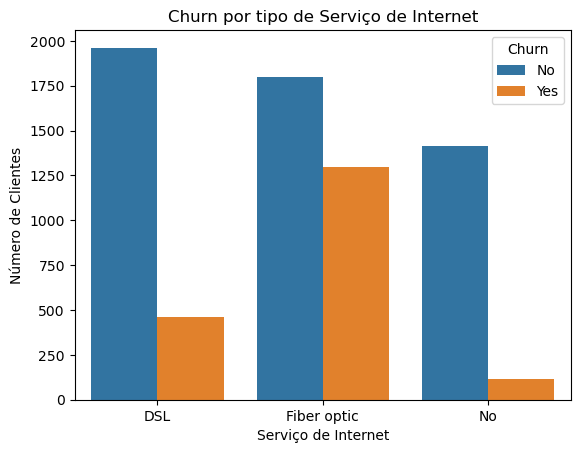

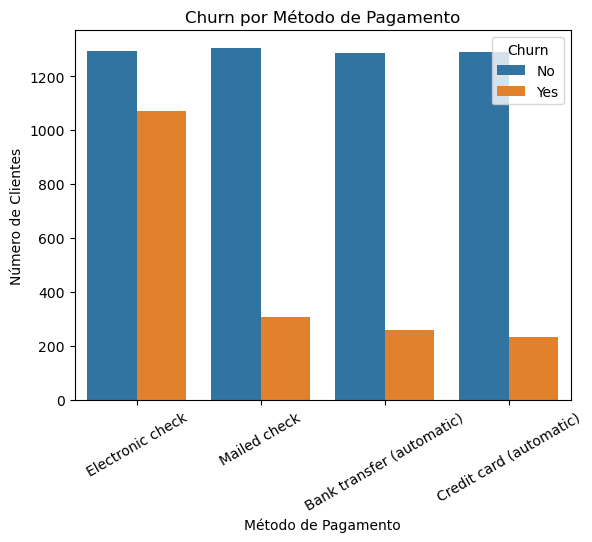

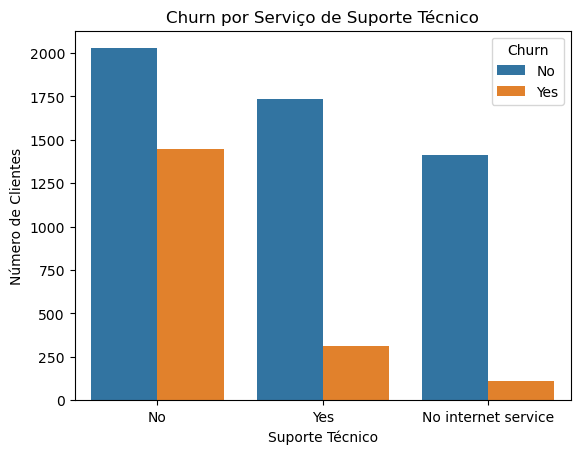

X: (7043, 20)
y: (7043,)

Treino: (4930, 20)
Validação: (1056, 20)
Teste: (1057, 20)

Treino: 0.6999858015050404
Validação: 0.1499361067726821
Teste: 0.15007809172227743

Distribuição no conjunto de treino:
Churn
0    73.46856
1    26.53144
Name: proportion, dtype: float64

Distribuição no conjunto de validação:
Churn
0    73.484848
1    26.515152
Name: proportion, dtype: float64

Distribuição no conjunto de teste:
Churn
0    73.415326
1    26.584674
Name: proportion, dtype: float64

Variáveis numéricas:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Variáveis categóricas:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'tenure_group']

Treino: (4930, 19)
Validação: (1056, 19)
Teste: (1057, 19)

Regressão Logística
Accuracy: 0.8087
Precision: 0.6523
Recall: 0.5964
F1-score: 0.6231


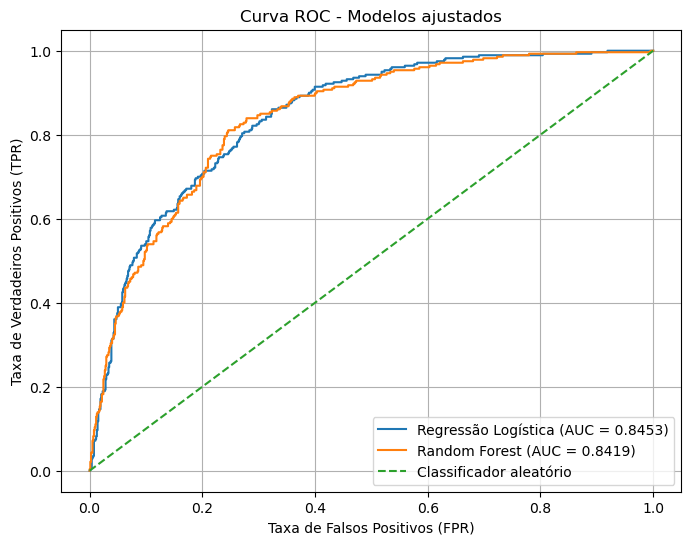


Matriz de confusão - Regressão Logística
[[686  90]
 [114 166]]

Matriz de confusão - Random Forest
[[697  79]
 [130 150]]


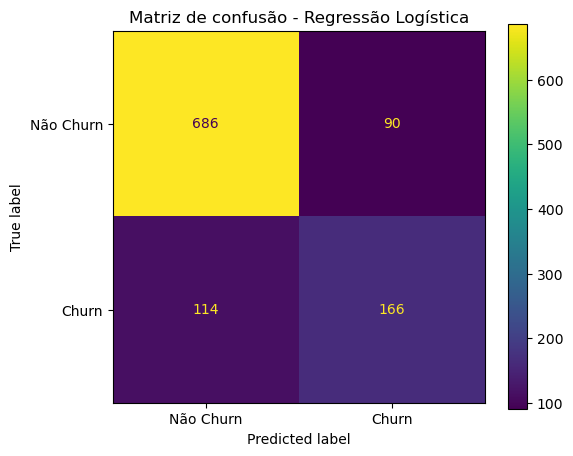


Número de variáveis após preprocessing: 30


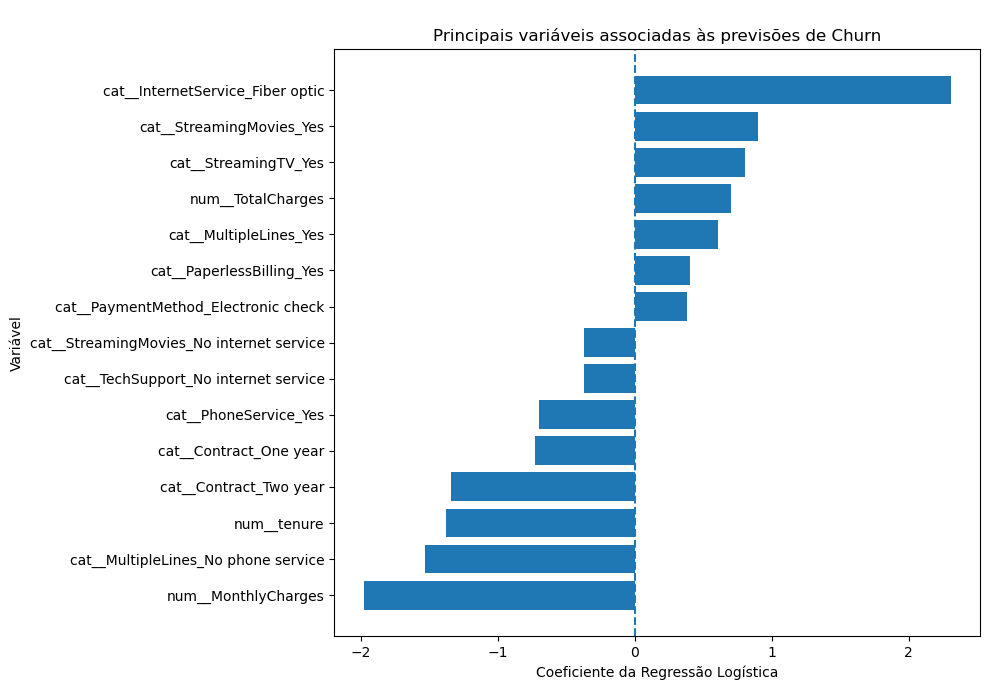


Avaliação final - Regressão Logística
Accuracy: 0.8098
Precision: 0.6869
Recall: 0.5231
F1-score: 0.5939
ROC-AUC: 0.8446

Matriz de Confusão:
[[709  67]
 [134 147]]


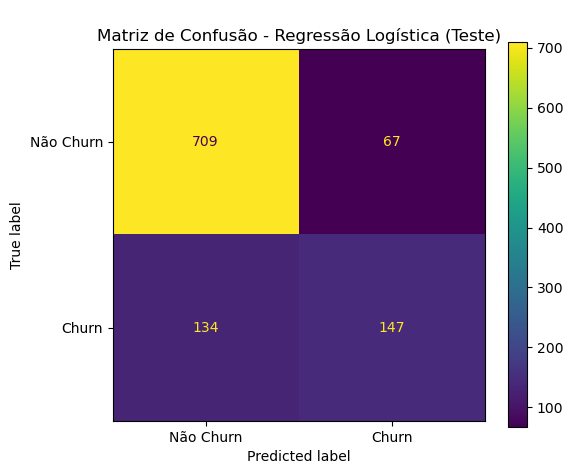

,Métrica,Validação,Teste
0,Accuracy,0.8068,0.8098
1,Precision,0.6484,0.6869
2,Recall,0.5929,0.5231
3,F1-score,0.6194,0.5939
4,ROC-AUC,0.8453,0.8446


In [87]:
# Carregamento dos dados
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Leitura do arquivo csv com os dados
df = pd.read_csv("../dados/WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Mostrar as 5 primeiras linhas para ver se é o arquivo correto
df.head()

# Para saber o tamanho do DataFrame, quantas linhas e colunas
df.shape

# Descrição dos dados
df.info()

# Para saber os tipos de dados
df.dtypes

#Para encontrar os valores ausentes
df.isnull().sum()
df.isnull().sum()[df.isnull().sum() > 0]
df.isna().sum()

# Para ver as estatísticas das variáveis numéricas
df.describe()

#Para analisar quantos clientes abandonaram
df["Churn"].value_counts(normalize=True) * 100

# Verificar se existem linhas duplicadas
df.duplicated().sum()

#Verificar se existem customerID duplicados
df["customerID"].duplicated().sum()

#Verificar número de valores únicos por variável
df.nunique()

#Valores existentes nas variáveis categóricas
for coluna in df.select_dtypes(include="object").columns:
    print(f"\n{coluna}:")
    print(df[coluna].unique())

# Identificar valores que não são numéricos em TotalCharges
pd.to_numeric(df["TotalCharges"], errors="coerce").isna().sum()

#Encontrar clientes em que o TotalCharge não consegue ser interpretado como número
df.loc[pd.to_numeric(df["TotalCharges"], errors="coerce").isna(), ["customerID", "tenure", "TotalCharges", "Churn"]]

# Converter TotalCharges para numérico
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

#Substituir os valores ausentes de TotalCharges por 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Verificando os dados
df.dtypes

# Verificando novamente os valores ausentes
df.isnull().sum()

# Identificar variáveis numéricas (outliers)
df.select_dtypes(include=np.number).columns

# Boxplots das variáveis numéricas
df.select_dtypes(include=np.number).boxplot(figsize=(10,6))
plt.title("Distribuição das variáveis numéricas")
plt.xticks(rotation=45)
plt.show()

# Distribuição de Churn
sns.countplot(data=df, x="Churn")
plt.title("Distribuição de clientes por Churn")
plt.xlabel("Churn")
plt.ylabel("Número de clientes")
plt.show()

# Guardar quantidades
df["Churn"].value_counts()

# Analisar possibilidades que influenciam o Churn
# Contrato (variável categórica)
pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

# Montando o gráfico
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Churn por tipo de contrato")
plt.xlabel("Tipo de Contrato")
plt.ylabel("Número de Clientes")
plt.xticks(rotation=15)
plt.show()

# Tempo como cliente (gráfico, variável numérica)
sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Tempo de Cliente por Churn")
plt.xlabel("Churn")
plt.ylabel("Meses como Cliente")
plt.show()

# Criar grupos de tenure apenas para análise exploratória
# Esta variável não será utilizada nos modelos, pois é derivada de "tenure"
df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[0, 12, 24, 48, 72],
    labels=["0-12 meses", "13-24 meses", "25-48 meses", "49-72 meses"]
)
pd.crosstab(
    df["tenure_group"],
    df["Churn"],
    normalize="index"
) * 100

# Gráfico
sns.countplot(data=df, x="tenure_group", hue="Churn")
plt.title("Churn por Tempo como CLiente")
plt.xlabel("Tempo como Cliente")
plt.ylabel("Número de Clientes")
plt.show()

# Mensalidade (gráfico, variável numérica)
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Mensalidade por Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

# Internet Service (variável categórica)
pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

#Gráfico
sns.countplot(data=df, x="InternetService", hue="Churn")
plt.title("Churn por tipo de Serviço de Internet")
plt.xlabel("Serviço de Internet")
plt.ylabel("Número de Clientes")
plt.show()

# Payment Method (variável categórica)
pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

#Gráfico
sns.countplot(data=df, x="PaymentMethod", hue="Churn")
plt.title("Churn por Método de Pagamento")
plt.xlabel("Método de Pagamento")
plt.ylabel("Número de Clientes")
plt.xticks(rotation=30)
plt.show()

# Análise para Tech Support (variável categórica)
pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

# Gráfico
sns.countplot(data=df, x="TechSupport", hue="Churn")
plt.title("Churn por Serviço de Suporte Técnico")
plt.xlabel("Suporte Técnico")
plt.ylabel("Número de Clientes")
plt.show()

# Remover o identificador do cliente
df = df.drop("customerID", axis=1)

# Verificar as colunas restantes
df.columns

# Separar as variáveis explicativas (X) da variável alvo (y)
X = df.drop("Churn", axis=1)
y = df["Churn"]

# Verificação
print("X:", X.shape)
print("y:", y.shape)

# Converter Churn para valores numéricos (0 e 1) para depois utilizar nas métricas
y = y.map({
    "No": 0,
    "Yes": 1,
})
# Verificar o resultado
y.value_counts()

# Mostrar o valor numérico de Churn
y.head()

# Divisão de dados
from sklearn.model_selection import train_test_split

# Primeira divisão: 70% treino e 30% temporário
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Segunda divisão: 50% validação e 50% teste
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Verificando as divisões
print("\nTreino:", X_train.shape)
print("Validação:", X_val.shape)
print("Teste:", X_test.shape)

# Confirmando as proporções
print("\nTreino:", len(X_train)/len(X))
print("Validação:", len(X_val)/len(X))
print("Teste:", len(X_test)/len(X))

# Confirmar o balanceamento
print("\nDistribuição no conjunto de treino:")
print(y_train.value_counts(normalize=True) * 100)
print("\nDistribuição no conjunto de validação:")
print(y_val.value_counts(normalize=True) * 100)
print("\nDistribuição no conjunto de teste:")
print(y_test.value_counts(normalize=True) * 100)

# Identificar variáveis numéricas e categóricas
numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns
categorical_features = X_train.select_dtypes(include=["object", "category"]).columns

print("\nVariáveis numéricas:")
print(list(numeric_features))
print("\nVariáveis categóricas:")
print(list(categorical_features))

# Remover tenure_group antes da modelação, pois será utilizada apenas na EDA
X = X.drop("tenure_group", axis=1)

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("\nTreino:", X_train.shape)
print("Validação:", X_val.shape)
print("Teste:", X_test.shape)

#Standardização e One-Hot Encoding
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identificar novamente as variáveis
numeric_features = X_train.select_dtypes(include=["int64", "float64"]).columns
categorical_features = X_train.select_dtypes(include=["object", "category"]).columns

# Criar o pré-processador
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            drop="first"
        ), categorical_features)
    ]
)

# Criação de Pipeline para ligar o pré-processamento aos modelos
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Pipeline da Regressão Logística
logreg_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

# Pipeline da Random Forest
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=42))
])

# Treinar Regressão Logística
logreg_pipeline.fit(X_train, y_train)

#Treinar Random Forest
rf_pipeline.fit(X_train, y_train)

# Fazer previsões na validação
y_val_pred_logreg = logreg_pipeline.predict(X_val)
y_val_pred_rf = rf_pipeline.predict(X_val)

# Obter a probalidade de Churn
y_val_prob_logreg = logreg_pipeline.predict_proba(X_val)[:, 1]
y_val_prob_rf = rf_pipeline.predict_proba(X_val)[:, 1]

# Avaliação dos modelos
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Regressão Logística
accuracy_logreg = accuracy_score(y_val, y_val_pred_logreg)
precision_logreg = precision_score(y_val, y_val_pred_logreg)
recall_logreg = recall_score(y_val, y_val_pred_logreg)
f1_logreg = f1_score(y_val, y_val_pred_logreg)

# Random Forest
accuracy_rf = accuracy_score(y_val, y_val_pred_rf)
precision_rf = precision_score(y_val, y_val_pred_rf)
recall_rf = recall_score(y_val, y_val_pred_rf)
f1_rf = f1_score(y_val, y_val_pred_rf)

print("\nRegressão Logística")
print(f"Accuracy: {accuracy_logreg:.4f}")
print(f"Precision: {precision_logreg:.4f}")
print(f"Recall: {recall_logreg:.4f}")
print(f"F1-score: {f1_logreg:.4f}")

print("\nRandom Forest")
print(f"Accuracy: {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall: {recall_rf:.4f}")
print(f"F1-score: {f1_rf:.4f}")

# Utilização de GridSearchCV
from sklearn.model_selection import GridSearchCV

param_grid_logreg = {"model__C": [0.01, 0.1, 1, 10, 100]}

grid_logreg = GridSearchCV(
    logreg_pipeline,
    param_grid=param_grid_logreg,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_logreg.fit(X_train, y_train)

print("\nMelhores parâmetros:")
print(grid_logreg.best_params_)

print("\nMelhor F1-score:")
print(grid_logreg.best_score_)

# Ajustar Random Forest
param_grid_rf = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2]
}

grid_rf = GridSearchCV(
    rf_pipeline,
    param_grid=param_grid_rf,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)

print("\nMelhores parâmetros:")
print(grid_rf.best_params_)
print("\nMelhor F1-score:")
print(grid_rf.best_score_)

# Obter os melhores modelos
best_logreg = grid_logreg.best_estimator_
best_rf = grid_rf.best_estimator_

# Fazer previsões no conjunto de validação
y_val_pred_logreg_tuned = best_logreg.predict(X_val)
y_val_pred_rf_tuned = best_rf.predict(X_val)

y_val_prob_logreg_tuned = best_logreg.predict_proba(X_val)[:, 1]
y_val_prob_rf_tuned = best_rf.predict_proba(X_val)[:, 1]

# Avaliando os dois modelos ajustados
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Regressão Logística ajustada
accuracy_logreg_tuned = accuracy_score(y_val, y_val_pred_logreg_tuned)
precision_logreg_tuned = precision_score(y_val, y_val_pred_logreg_tuned)
recall_logreg_tuned = recall_score(y_val, y_val_pred_logreg_tuned)
f1_logreg_tuned = f1_score(y_val, y_val_pred_logreg_tuned)

# Random Forest ajustado
accuracy_rf_tuned = accuracy_score(y_val, y_val_pred_rf_tuned)
precision_rf_tuned = precision_score(y_val, y_val_pred_rf_tuned)
recall_rf_tuned = recall_score(y_val, y_val_pred_rf_tuned)
f1_rf_tuned = f1_score(y_val, y_val_pred_rf_tuned)

print("\nRegressão Logística ajustada:")
print(f"Accuracy: {accuracy_logreg_tuned:.4f}")
print(f"Precision: {precision_logreg_tuned:.4f}")
print(f"Recall: {recall_logreg_tuned:.4f}")
print(f"F1-score: {f1_logreg_tuned:.4f}")

print("\nRandom Forest ajustado:")
print(f"Accuracy: {accuracy_rf_tuned:.4f}")
print(f"Precision: {precision_rf_tuned:.4f}")
print(f"Recall: {recall_rf_tuned:.4f}")
print(f"F1-score: {f1_rf_tuned:.4f}")

# Cálculo ROC-AUC
from sklearn.metrics import roc_auc_score

auc_logreg = roc_auc_score(y_val, y_val_prob_logreg_tuned)
auc_rf = roc_auc_score(y_val, y_val_prob_rf_tuned)

print("\nROC-AUC Regressão Logística:", round(auc_logreg, 4))
print("\nROC-AUC Random Forest:", round(auc_rf, 4))

# Criar curva ROC
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr_logreg, tpr_logreg, _ = roc_curve(y_val, y_val_prob_logreg_tuned)
fpr_rf, tpr_rf, _ = roc_curve(y_val, y_val_prob_rf_tuned)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_logreg,
    tpr_logreg,
    label=f"Regressão Logística (AUC = {auc_logreg:.4f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {auc_rf:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Classificador aleatório"
)

plt.xlabel("Taxa de Falsos Positivos (FPR)")
plt.ylabel("Taxa de Verdadeiros Positivos (TPR)")
plt.title("Curva ROC - Modelos ajustados")
plt.legend()
plt.grid()
plt.show()

# Matriz de Confusão
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_logreg = confusion_matrix(y_val, y_val_pred_logreg_tuned)
cm_rf = confusion_matrix(y_val, y_val_pred_rf_tuned)

print("\nMatriz de confusão - Regressão Logística")
print(cm_logreg)

print("\nMatriz de confusão - Random Forest")
print(cm_rf)

# Visualizando as matrizes
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm_logreg,
    display_labels=["Não Churn", "Churn"]
).plot(ax=ax)

plt.title("Matriz de confusão - Regressão Logística")
plt.show()

# Comparação Final
resultados = pd.DataFrame({
    "Modelo": [
        "Regressão Logística",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_logreg_tuned,
        accuracy_rf_tuned
    ],
    "Precision": [
        precision_logreg_tuned,
        precision_rf_tuned
    ],
    "Recall": [
        recall_logreg_tuned,
        recall_rf_tuned
    ],
    "F1-score": [
        f1_logreg_tuned,
        f1_rf_tuned
    ],
    "ROC-AUC": [
        auc_logreg,
        auc_rf
    ]
})
resultados.round(4)

# Quais variáveis estão mais associadas às previsões de Churn
feature_names = best_logreg.named_steps["preprocessor"].get_feature_names_out()
print("\nNúmero de variáveis após preprocessing:", len(feature_names))

# Coeficientes da Regressão Logística
coefficients = best_logreg.named_steps["model"].coef_[0]

coef_df = pd.DataFrame({"Variável": feature_names, "Coeficiente": coefficients})

coef_df["Valor_absoluto"] = coef_df["Coeficiente"].abs()

coef_df = coef_df.sort_values("Valor_absoluto", ascending=False)

coef_df.head(15)

# Gráfico com as 15 variáveis de maior influência
top_features = coef_df.head(15).sort_values("Coeficiente")

plt.figure(figsize=(10,7))

plt.barh(top_features["Variável"], top_features["Coeficiente"])

plt.axvline(0, linestyle="--")

plt.xlabel("Coeficiente da Regressão Logística")
plt.ylabel("Variável")
plt.title("\nPrincipais variáveis associadas às previsões de Churn")

plt.tight_layout()
plt.show()

# Avaliar a Regressão Logísticano teste
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
y_test_pred = best_logreg.predict(X_test)
y_test_prob = best_logreg.predict_proba(X_test)[:, 1]

accuracy_test = accuracy_score(y_test, y_test_pred)
precision_test = precision_score(y_test, y_test_pred)
recall_test = recall_score(y_test, y_test_pred)
f1_test = f1_score(y_test, y_test_pred)
auc_test = roc_auc_score(y_test, y_test_prob)

print("\nAvaliação final - Regressão Logística")
print(f"Accuracy: {accuracy_test:.4f}")
print(f"Precision: {precision_test:.4f}")
print(f"Recall: {recall_test:.4f}")
print(f"F1-score: {f1_test:.4f}")
print(f"ROC-AUC: {auc_test:.4f}")

# Matriz de Confusão
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm_test = confusion_matrix(y_test, y_test_pred)

print("\nMatriz de Confusão:")
print(cm_test)

fig, ax = plt.subplots(figsize=(6,5))

ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=["Não Churn", "Churn"]).plot(ax=ax)

plt.title("\nMatriz de Confusão - Regressão Logística (Teste)")
plt.show()

# Comparação entre os resultados de validação e teste
comparacao_final = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Validação": [
        accuracy_logreg_tuned,
        precision_logreg_tuned,
        recall_logreg_tuned,
        f1_logreg_tuned,
        auc_logreg
    ],
    "Teste": [
        accuracy_test,
        precision_test,
        recall_test,
        f1_test,
        auc_test
    ]
})

comparacao_final.round(4)